# Bioluminescence scan

This notebook runs the active Jupyter kernel environment to scan nightly video folders from the NAS without downloading them. Full raw and classified CSVs are stored on the NAS; the repository keeps only prospective detections and compact provenance. Combined master CSVs are regenerated on the NAS for analysis. Existing raw nights are skipped unless added to `rerun_nights`, and only nights without classified results are classified.

Use the Run button (or Shift+Enter) to execute each cell.

## Set up paths 

In [1]:
import os
import subprocess
import sys
from pathlib import Path

# Find the analysis folder from either the repo root or a folder inside it.
cwd = Path.cwd().resolve()
analysis_dir = next(
    (candidate for parent in (cwd, *cwd.parents)
     for candidate in (parent / 'tank-bioluminescence-scan', parent)
     if (candidate / 'scan_bioluminescence.py').is_file()
     and (candidate / 'classify_bioluminescence.py').is_file()),
    None,
)
if analysis_dir is None:
    raise FileNotFoundError(
        'Cannot find the analysis scripts. Open this notebook from the '
        'manta-analysis repository and use a kernel working directory inside it.'
    )
if str(analysis_dir) not in sys.path:
    sys.path.insert(0, str(analysis_dir))
from nightly_bioluminescence import default_nas_output_dir, nas_mountpoint

script = analysis_dir / 'scan_bioluminescence.py'
nas_root = nas_mountpoint()
data_mount = nas_root / 'aquarium'
data_root = data_mount / '2026Pan'
if not data_root.is_dir():
    raise FileNotFoundError(f'NAS video folder is missing: {data_root}')
output_dir = default_nas_output_dir()
results_dir = analysis_dir / 'results'
provenance_dir = analysis_dir / 'provenance'
output_dir.mkdir(parents=True, exist_ok=True)
results_dir.mkdir(parents=True, exist_ok=True)
provenance_dir.mkdir(parents=True, exist_ok=True)

print('scan script:', script)
print('script exists:', script.is_file())
print('data mount:', data_mount)
excluded_nights = {'20261110'}
night_dirs = sorted(p for p in data_root.iterdir() if p.is_dir() and p.name.isdigit() and len(p.name) == 8 and p.name not in excluded_nights)
print('nights found:', [p.name for p in night_dirs])
print('output dir:', output_dir)

scan script: /home/local/ADS/oakley/github/manta-analysis/tank-bioluminescence-scan/scan_bioluminescence.py
script exists: True
data mount: /home/local/ADS/oakley/labdata/aquarium
nights found: ['20261111', '20261112', '20261113', '20261114', '20261115', '20261116', '20261117', '20261118', '20261119', '20261121', '20261122', '20261123', '20261124', '20261125', '20261126']
output dir: /home/local/ADS/oakley/labdata/analysis/manta-analysis/tank-bioluminescence-scan/output


## Scan video - use rerun_nights to rescan

In [3]:
import pandas as pd
import shutil
import subprocess
import sys
import tempfile
if str(analysis_dir) not in sys.path:
    sys.path.insert(0, str(analysis_dir))

from nightly_bioluminescence import (
    list_night_csvs, night_csv_path, rebuild_master_csv,
    split_master_csv_by_night, write_scanned_night,
)

conda_python = sys.executable
master_csv = output_dir / 'bioluminescence_hits.csv'
analysis_log = output_dir / 'analyzed_nights.txt'
rerun_nights = {'20261126'} # example: {'20261117'}
raw_night_files = list_night_csvs(output_dir)
if not raw_night_files and master_csv.exists():
    split_master_csv_by_night(master_csv, output_dir)
raw_changed = False
analyzed_nights = set(analysis_log.read_text().splitlines()) if analysis_log.exists() else set()

for night_dir in night_dirs:
    night = night_dir.name
    night_csv = night_csv_path(output_dir, night)
    if night_csv.exists() and night not in rerun_nights:
        print(f'Skipping scan for {night}: {night_csv} already exists')
        continue

    staging_dir = Path(tempfile.mkdtemp(prefix=f'bioluminescence_{night}_', dir=output_dir))
    cmd = [
        conda_python, str(script), str(night_dir),
        '--output', str(staging_dir),
        '--sample-rate-hz', '2.5',
        '--black', '150',
        '--min-area', '20',
        '--max-area', '1000',
        '--brightness-threshold', '35',
        '--exclude-roi', '0.05,0.50,0.08,0.65',
        '--thumb-time-gap-sec', '5',
        '--thumb-position-gap-px', '15',
    ]
    try:
        print(f'\nScanning night {night}: {night_dir}')
        result = subprocess.run(cmd, text=True)
        if result.returncode != 0:
            print(f'Scan failed for {night}; leaving existing per-night results unchanged')
            continue

        staged_csv = staging_dir / 'bioluminescence_hits.csv'
        if not staged_csv.exists():
            print(f'No CSV produced for {night}; leaving existing per-night results unchanged')
            continue
        night_csv, detection_count = write_scanned_night(staged_csv, output_dir, night)
        raw_changed = True
        analyzed_nights.add(night)
        analysis_log.write_text('\n'.join(sorted(analyzed_nights)) + '\n')

        master_thumb_dir = output_dir / 'thumbs'
        master_thumb_dir.mkdir(parents=True, exist_ok=True)
        for old_thumb in master_thumb_dir.glob(f'{night}_*.png'):
            old_thumb.unlink()
        for thumb in (staging_dir / 'thumbs').glob('*.png'):
            shutil.copy2(thumb, master_thumb_dir / f'{night}_{thumb.name}')
        for lighting_name in ('lighting_samples.csv', 'lighting_transitions.csv'):
            lighting_file = staging_dir / lighting_name
            if lighting_file.exists():
                shutil.copy2(lighting_file, output_dir / f'{night}_{lighting_name}')
        print(f'Wrote {detection_count} detections to {night_csv}')
    finally:
        shutil.rmtree(staging_dir, ignore_errors=True)

if raw_changed or not master_csv.exists():
    raw_count = rebuild_master_csv(output_dir, master_csv)
    print(f'Rebuilt raw master CSV with {raw_count} detections')

lighting_transition_files = sorted(output_dir.glob('*_lighting_transitions.csv'))
if lighting_transition_files:
    pd.concat([pd.read_csv(path) for path in lighting_transition_files], ignore_index=True).to_csv(output_dir / 'lighting_transitions.csv', index=False)
print(f'Master CSV: {master_csv}')
print(f'Lighting transitions: {output_dir / "lighting_transitions.csv" if lighting_transition_files else "none"}')

Skipping scan for 20261111: /home/local/ADS/oakley/labdata/analysis/manta-analysis/tank-bioluminescence-scan/output/20261111_hits.csv already exists
Skipping scan for 20261112: /home/local/ADS/oakley/labdata/analysis/manta-analysis/tank-bioluminescence-scan/output/20261112_hits.csv already exists
Skipping scan for 20261113: /home/local/ADS/oakley/labdata/analysis/manta-analysis/tank-bioluminescence-scan/output/20261113_hits.csv already exists
Skipping scan for 20261114: /home/local/ADS/oakley/labdata/analysis/manta-analysis/tank-bioluminescence-scan/output/20261114_hits.csv already exists
Skipping scan for 20261115: /home/local/ADS/oakley/labdata/analysis/manta-analysis/tank-bioluminescence-scan/output/20261115_hits.csv already exists
Skipping scan for 20261116: /home/local/ADS/oakley/labdata/analysis/manta-analysis/tank-bioluminescence-scan/output/20261116_hits.csv already exists
Skipping scan for 20261117: /home/local/ADS/oakley/labdata/analysis/manta-analysis/tank-bioluminescence-sc

## Compile csv files from multiple nights

In [4]:
import pandas as pd
from pathlib import Path

combined_csv = output_dir / 'bioluminescence_hits.csv'
csv_files = [combined_csv] if combined_csv.exists() else sorted(output_dir.glob('*_hits.csv'))
print('CSV files found:', csv_files)
frames = [pd.read_csv(csv_file) for csv_file in csv_files]
df = pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()
print('Total detections:', len(df))
display(df)

CSV files found: [PosixPath('/home/local/ADS/oakley/labdata/analysis/manta-analysis/tank-bioluminescence-scan/output/bioluminescence_hits.csv')]
Total detections: 6124806


,night,video,frame,time_sec,x,y,y_flipped,area,min_intensity,max_intensity,mean_intensity,bbox_x,bbox_y,bbox_width,bbox_height
0,20261111,/Volumes/oakley_lab/aquarium/2026Pan/20261111/...,17262,1150.800,1117,555,525,41.5,151.0,255.0,230.727,1114,551,7,11
1,20261111,/Volumes/oakley_lab/aquarium/2026Pan/20261111/...,17268,1151.200,1109,559,521,80.0,150.0,255.0,230.269,1107,547,6,23
2,20261111,/Volumes/oakley_lab/aquarium/2026Pan/20261111/...,17274,1151.600,1103,555,525,69.0,150.0,255.0,233.871,1101,544,6,22
3,20261111,/Volumes/oakley_lab/aquarium/2026Pan/20261111/...,17280,1152.000,1097,552,528,57.0,152.0,255.0,224.615,1095,542,6,20
4,20261111,/Volumes/oakley_lab/aquarium/2026Pan/20261111/...,17328,1155.200,1155,972,108,44.5,158.0,255.0,224.017,1152,968,8,12
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6124801,20261126,/home/local/ADS/oakley/labdata/aquarium/2026Pa...,53928,1797.566,1255,944,136,22.5,150.0,176.0,157.057,1253,941,6,10
6124802,20261126,/home/local/ADS/oakley/labdata/aquarium/2026Pa...,53928,1797.566,1238,946,134,249.5,150.0,179.0,158.125,1228,931,22,28
6124803,20261126,/home/local/ADS/oakley/labdata/aquarium/2026Pa...,53928,1797.566,1221,939,141,60.5,150.0,211.0,156.402,1211,930,19,16
6124804,20261126,/home/local/ADS/oakley/labdata/aquarium/2026Pa...,53928,1797.566,1272,935,145,130.0,150.0,174.0,153.602,1262,928,30,17


## Plot old style file formats (no timestamps)

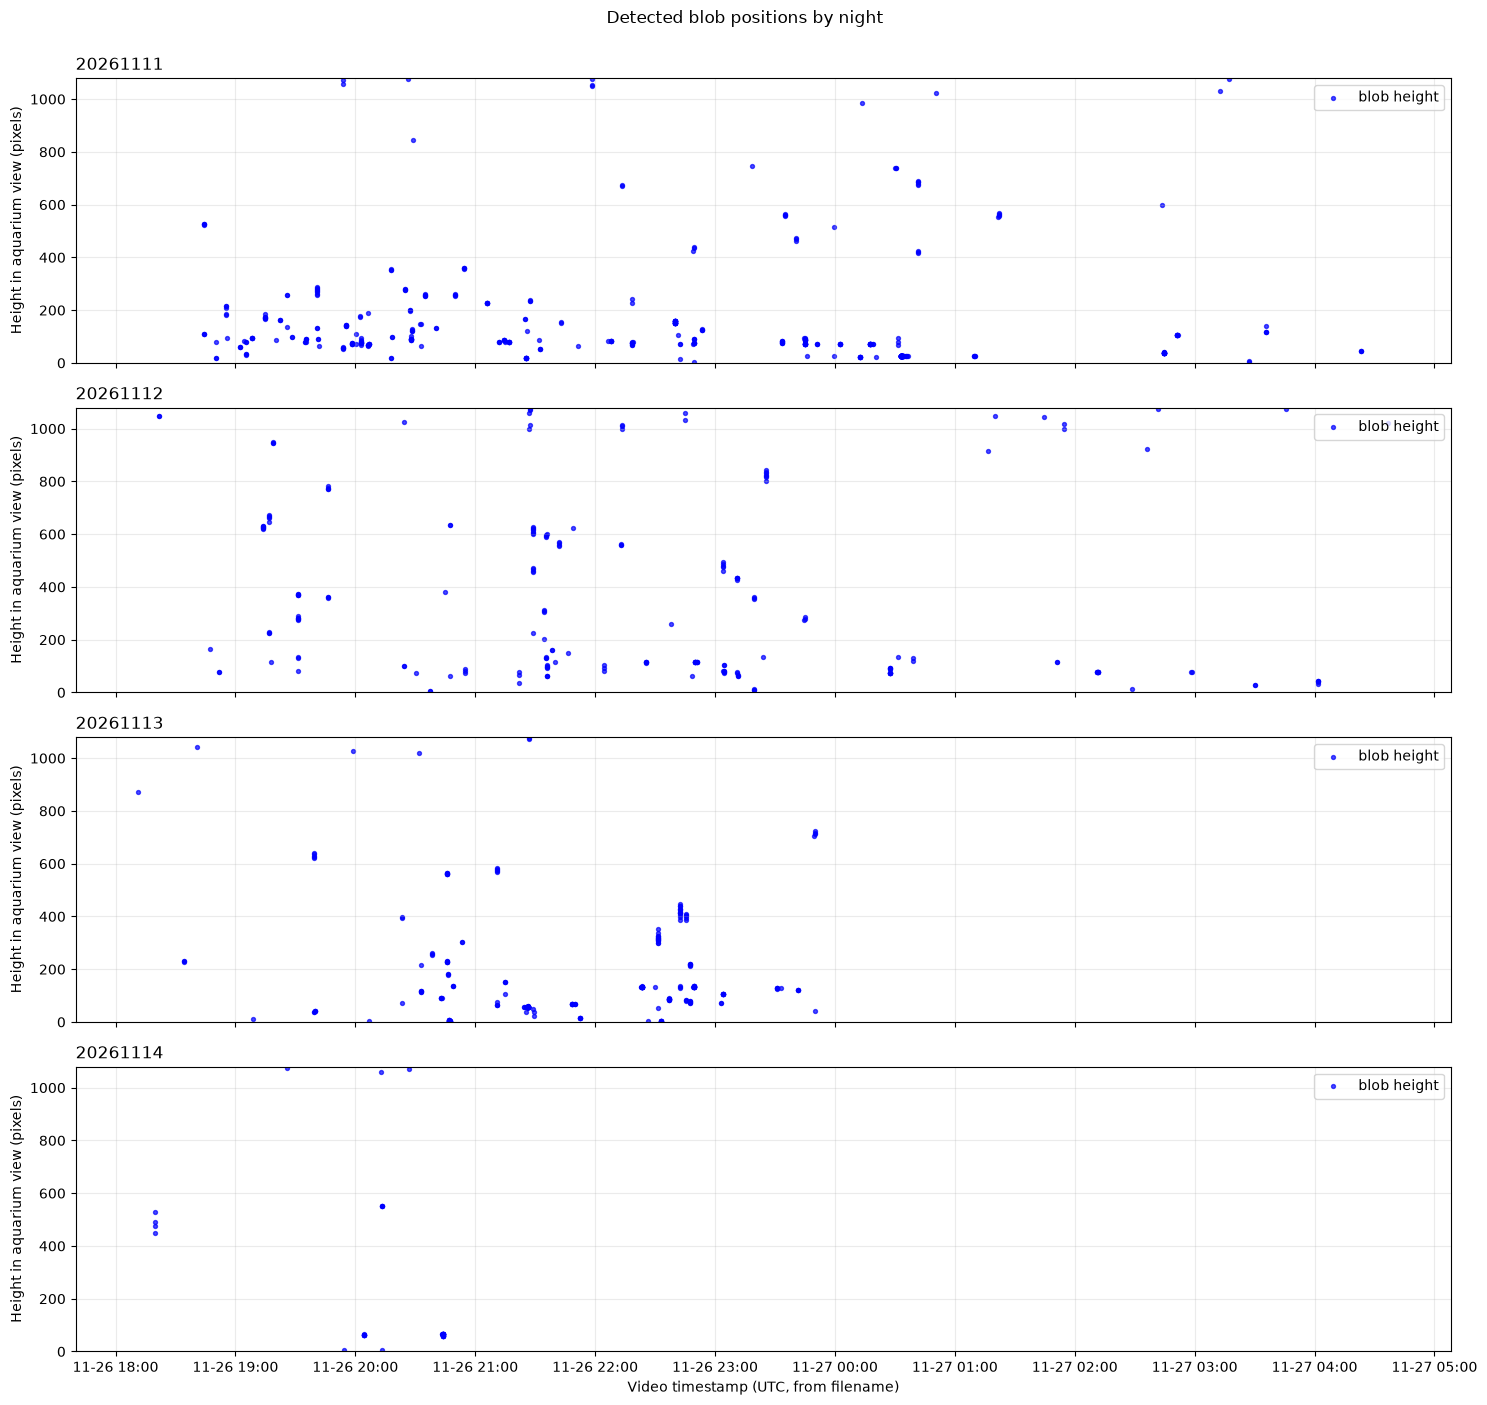

In [12]:
import re
from datetime import datetime, time, timedelta
from pathlib import Path
import cv2
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd

combined_csv = output_dir / 'bioluminescence_hits.csv'
if combined_csv.exists():
    df = pd.read_csv(combined_csv)

if 'df' not in globals() or df.empty:
    print('No detections to plot.')
else:
    def video_key(path):
        name = Path(path).name
        legacy = re.search(r'output_(\d+)\.[^.]+$', name)
        if legacy:
            return (0, int(legacy.group(1)))
        timestamp = re.search(r'(20\d{6}T\d{6}Z)', name)
        return (1, timestamp.group(1)) if timestamp else (2, name)

    def video_start(path):
        match = re.search(r'(20\d{6}T\d{6}Z)', Path(path).name)
        return datetime.strptime(match.group(1), '%Y%m%dT%H%M%SZ') if match else None

    def legacy_number(path):
        match = re.search(r'output_(\d+)\.[^.]+$', Path(str(path)).name)
        return int(match.group(1)) if match else None

    def video_duration(video_path):
        cap = cv2.VideoCapture(str(video_path))
        fps = cap.get(cv2.CAP_PROP_FPS) or 0
        frame_count = cap.get(cv2.CAP_PROP_FRAME_COUNT)
        cap.release()
        return frame_count / fps if fps > 0 and frame_count > 0 else 26 * 60

    if 'night' not in df.columns:
        normalized_video = df['video'].str.replace('\\\\', '/', regex=False)
        df['night'] = normalized_video.str.extract(r'(?<!\d)(20\d{6})(?!\d)')[0]
    df['night'] = df['night'].astype(str)
    df = df[df['video'].map(legacy_number).notna()].copy()
    night_data = {}
    night_start_times = {}
    overall_max_sec = 0.0
    for night in sorted(df['night'].dropna().unique()):
        night_dir = data_root / night
        offsets = {}
        starts = {}
        elapsed = 0.0
        for path in sorted((p for p in night_dir.iterdir() if p.is_file() and p.suffix.lower() in {'.mp4', '.avi', '.mov', '.mkv', '.mts', '.wmv', '.m4v', '.ts'}), key=video_key):
            key = video_key(path)
            starts[key] = video_start(path)
        valid_starts = [value for value in starts.values() if value is not None]
        night_start = min(valid_starts) if valid_starts else datetime.combine(datetime.today(), time(17, 55))
        night_start_times[night] = night_start
        for path in sorted((p for p in night_dir.iterdir() if p.is_file() and p.suffix.lower() in {'.mp4', '.avi', '.mov', '.mkv', '.mts', '.wmv', '.m4v', '.ts'}), key=video_key):
            key = video_key(path)
            offsets[key] = (starts[key] - night_start).total_seconds() if starts[key] else elapsed
            elapsed = max(elapsed, offsets[key] + video_duration(path))
        night_df = df[df['night'] == night].copy()
        night_df['video_number'] = night_df['video'].map(video_key)
        night_df['night_elapsed_sec'] = night_df['time_sec'] + night_df['video_number'].map(offsets).fillna(0)
        night_data[night] = night_df
        overall_max_sec = max(overall_max_sec, elapsed)

    fig, axes = plt.subplots(len(night_data), 1, sharex=True, figsize=(15, max(4, 3.5 * len(night_data))))
    axes = [axes] if len(night_data) == 1 else list(axes)
    for ax, (night, night_df) in zip(axes, sorted(night_data.items())):
        clock_times = night_df['night_elapsed_sec'].map(lambda seconds: night_start_times[night] + timedelta(seconds=float(seconds)))
        ax.scatter(clock_times, night_df['y_flipped'], s=8, color='blue', alpha=0.7, label='blob height')
        ax.set_title(str(night), loc='left')
        ax.set_ylabel('Height in aquarium view (pixels)')
        ax.set_ylim(0, 1080)
        ax.grid(True, alpha=0.25)
        ax.legend(loc='upper right')
    axes[-1].set_xlabel('Video timestamp (UTC, from filename)')
    axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%m-%d %H:%M'))
    fig.suptitle('Detected blob positions by night', y=1.0)
    fig.tight_layout()
    plt.show()

## Classify blobs into sand reflection or luminous pulse

In [5]:
import shutil
import subprocess
import sys

if str(analysis_dir) not in sys.path:
    sys.path.insert(0, str(analysis_dir))

from nightly_bioluminescence import (
    classification_worklist, list_night_csvs, rebuild_candidate_csv,
    rebuild_master_csv,
    split_master_csv_by_night,
)
from classify_bioluminescence import SAND_REGION_FIELDS

classified_csv = output_dir / 'bioluminescence_hits_classified.csv'
reference_dir = output_dir / 'sand_references'
simulator_log = output_dir / 'simulator_log.csv'
classifier_script = analysis_dir / 'classify_bioluminescence.py'
if not list_night_csvs(output_dir, classified=True) and classified_csv.exists():
    split_master_csv_by_night(classified_csv, output_dir, classified=True)

configured_timezone = str(pd.read_csv(simulator_log, usecols=['simulator_timezone']).iloc[0, 0])
reclassify_nights = set()
for classified_path in list_night_csvs(output_dir, classified=True):
    night = classified_path.name[:-len('_hits_classified.csv')]
    columns = pd.read_csv(classified_path, nrows=0).columns
    if 'simulator_timezone' not in columns:
        reclassify_nights.add(night)
        continue
    stored_timezone = pd.read_csv(
        classified_path, usecols=['simulator_timezone'], nrows=1
    ).iloc[0, 0]
    if str(stored_timezone) != configured_timezone:
        reclassify_nights.add(night)
if reclassify_nights:
    print(f'Reclassifying {len(reclassify_nights)} nights for simulator timezone {configured_timezone}')
classified_worklist = classification_worklist(output_dir, reclassify_nights)
classified_changed = bool(classified_worklist)
for night, raw_csv, night_classified_csv in classified_worklist:
    print(f'Classifying night {night}: {raw_csv}')
    subprocess.run([
        sys.executable, str(classifier_script),
        '--input', str(raw_csv),
        '--output', str(night_classified_csv),
        '--reference-output', str(reference_dir / night),
        '--simulator-log', str(simulator_log),
    ], check=True, text=True)

region_files = sorted(reference_dir.glob('20??????/sand_regions.csv'))
if region_files:
    updated_nights = {path.parent.name for path in region_files}
    region_frames = [
        pd.read_csv(path) for path in region_files if path.stat().st_size > 1
    ]
    updated_regions = (
        pd.concat(region_frames, ignore_index=True)
        if region_frames else pd.DataFrame(columns=SAND_REGION_FIELDS)
    )
    master_regions_csv = reference_dir / 'sand_regions.csv'
    if master_regions_csv.exists() and master_regions_csv.stat().st_size > 1:
        existing_regions = pd.read_csv(master_regions_csv)
        existing_regions = existing_regions[
            ~existing_regions['night'].astype(str).isin(updated_nights)
        ]
        updated_regions = pd.concat(
            [existing_regions, updated_regions], ignore_index=True
        )
    updated_regions.to_csv(master_regions_csv, index=False)

master_regions_csv = reference_dir / 'sand_regions.csv'
if not master_regions_csv.exists():
    raise FileNotFoundError(f'No sand-region provenance available: {master_regions_csv}')
shutil.copy2(master_regions_csv, provenance_dir / 'sand_regions.csv')
shutil.copy2(simulator_log, provenance_dir / 'simulator_log.csv')
if classified_changed or not classified_csv.exists():
    classified_count = rebuild_master_csv(output_dir, classified_csv, classified=True)
    print(f'Rebuilt classified master CSV with {classified_count} detections')
if not classified_csv.exists():
    raise FileNotFoundError(f'No classified detections available: {classified_csv}')
candidate_csv = results_dir / 'bioluminescence_candidates.csv'
if classified_changed or not candidate_csv.exists():
    candidate_count = rebuild_candidate_csv(output_dir, candidate_csv)
    print(f'Wrote {candidate_count} prospective detections to {candidate_csv}')
else:
    print(f'Candidate detections are up to date: {candidate_csv}')

Classifying night 20261126: /home/local/ADS/oakley/labdata/analysis/manta-analysis/tank-bioluminescence-scan/output/20261126_hits.csv
Wrote 735997 classified detections to /home/local/ADS/oakley/labdata/analysis/manta-analysis/tank-bioluminescence-scan/output/20261126_hits_classified.csv
Wrote 3 sand reference regions to /home/local/ADS/oakley/labdata/analysis/manta-analysis/tank-bioluminescence-scan/output/sand_references/20261126/sand_regions.csv
classification
reflection_suspect    735993
uncertain                  4
Rebuilt classified master CSV with 6124806 detections
Wrote 5541 prospective detections to /home/local/ADS/oakley/github/manta-analysis/tank-bioluminescence-scan/results/bioluminescence_candidates.csv


## Plot nights with new fileformat (timestamps.)

Simulator log has no site_timezone; using America/Panama for lunar event times.


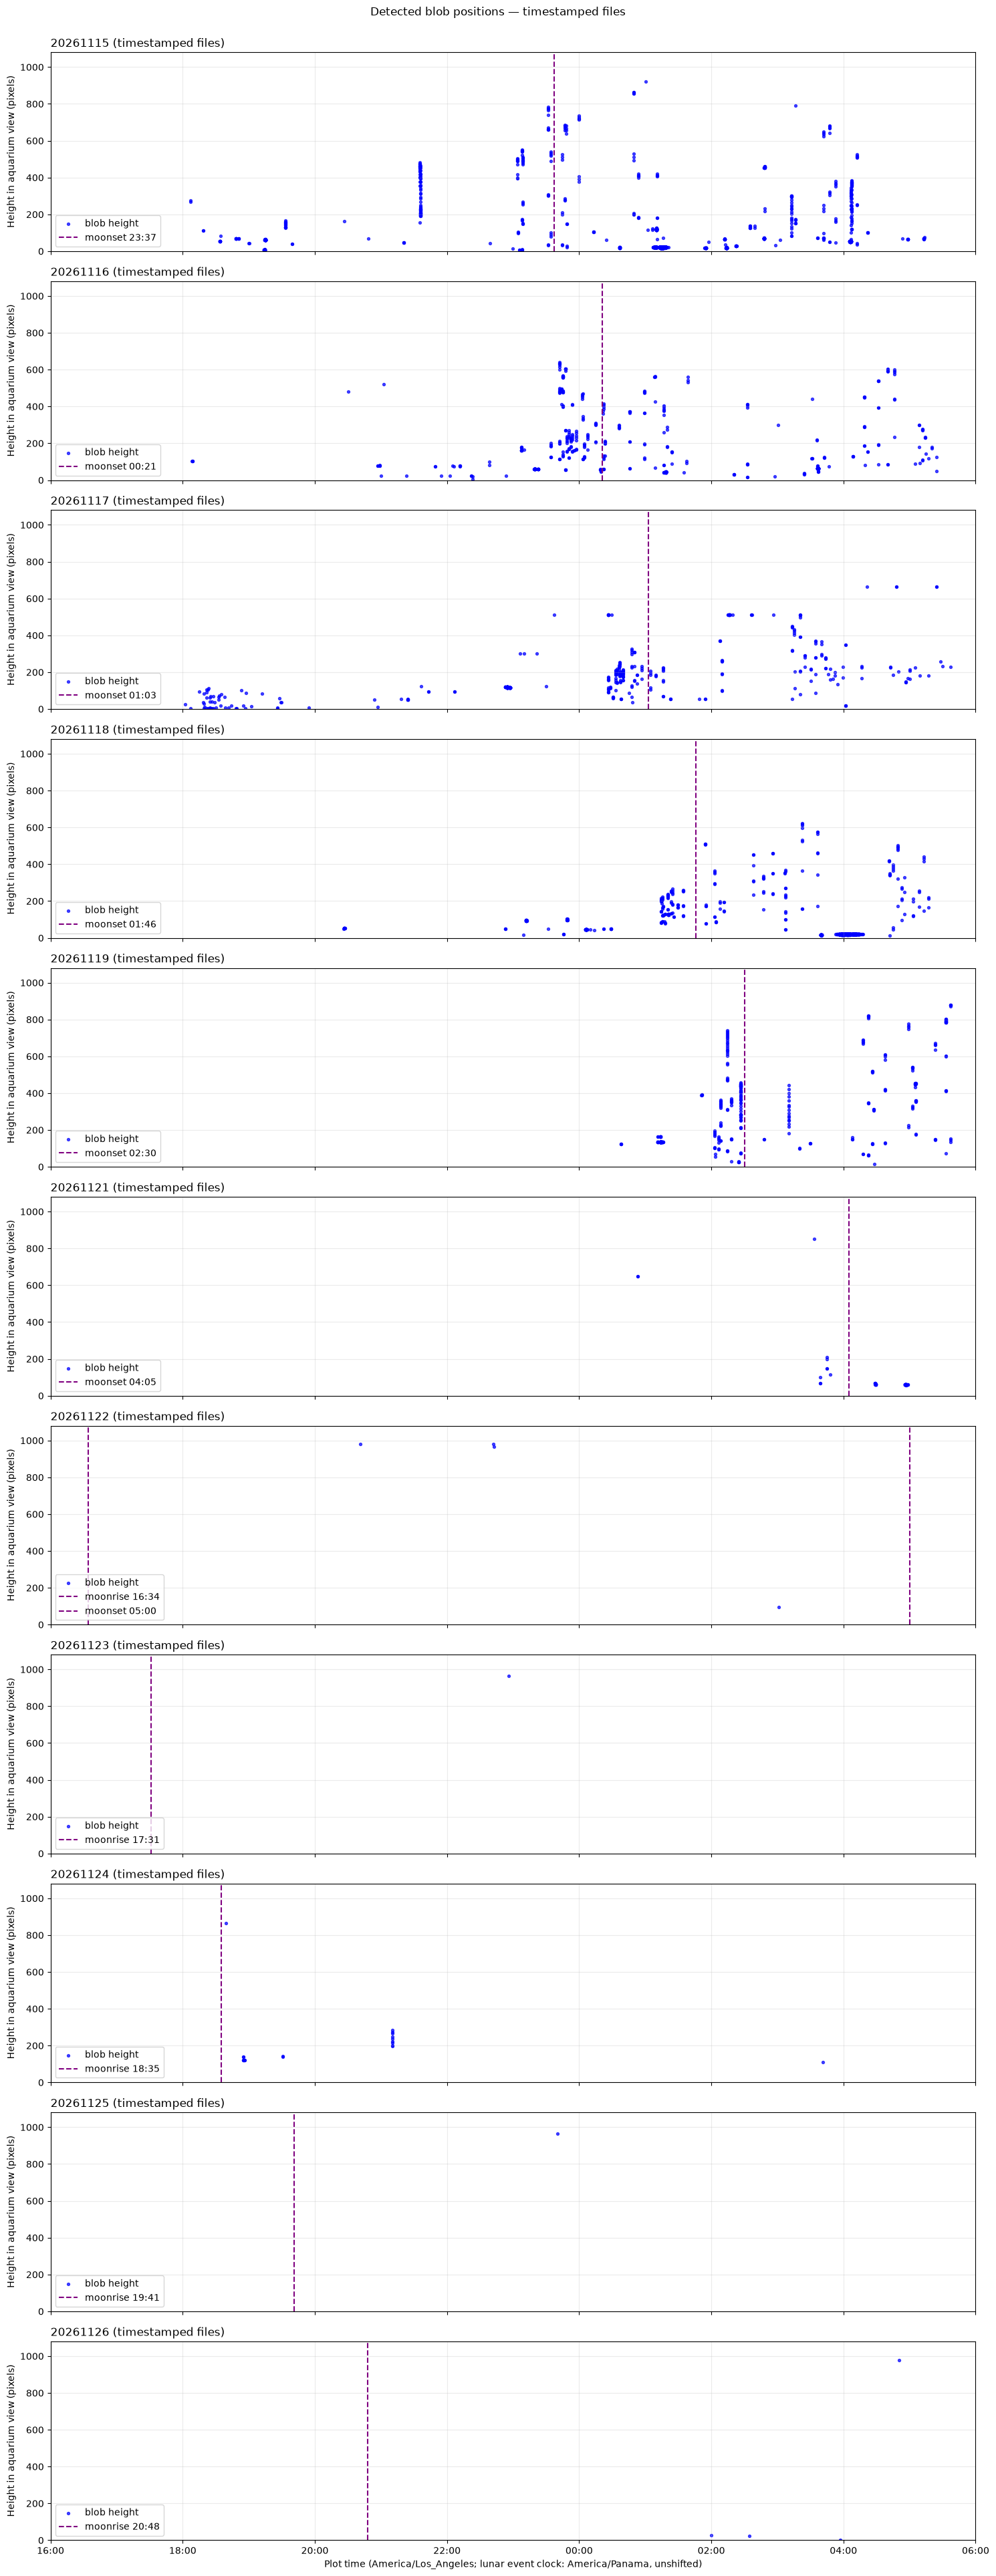

In [6]:
import re
from datetime import datetime, timedelta, timezone
from pathlib import Path
from zoneinfo import ZoneInfo
from astral import moon
from astral import Observer
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd

candidate_csv = results_dir / 'bioluminescence_candidates.csv'
if not candidate_csv.exists():
    raise FileNotFoundError(f'Candidate detections are missing: {candidate_csv}')
plot_csv = candidate_csv
simulator_settings = pd.read_csv(output_dir / 'simulator_log.csv').iloc[0]
DISPLAY_TZ_NAME = str(simulator_settings['display_timezone'])
if 'site_timezone' in simulator_settings.index:
    SITE_TZ_NAME = str(simulator_settings['site_timezone'])
else:
    SITE_TZ_NAME = 'America/Panama'
    print('Simulator log has no site_timezone; using America/Panama for lunar event times.')
SITE_TZ = ZoneInfo(SITE_TZ_NAME)
DISPLAY_TZ = ZoneInfo(DISPLAY_TZ_NAME)
df_timestamp = pd.read_csv(plot_csv)

def timestamp_from_video(value):
    match = re.search(r'(20\d{6}T\d{6}Z)', Path(str(value)).name)
    if not match:
        return None
    utc_time = datetime.strptime(match.group(1), '%Y%m%dT%H%M%SZ').replace(tzinfo=timezone.utc)
    return utc_time.astimezone(DISPLAY_TZ).replace(tzinfo=None)

SIMULATOR_OBSERVER = Observer(
    latitude=float(simulator_settings['simulator_latitude']),
    longitude=float(simulator_settings['simulator_longitude']),
    elevation=0,
)

def simulator_night_lunar_events(night):
    night_date = datetime.strptime(night, '%Y%m%d').date()
    night_start = datetime.combine(night_date, datetime.min.time()).replace(hour=18, tzinfo=SITE_TZ)
    window_start = night_start - timedelta(hours=2)
    window_end = night_start + timedelta(hours=12)
    first_utc_date = window_start.astimezone(timezone.utc).date() - timedelta(days=1)
    last_utc_date = window_end.astimezone(timezone.utc).date() + timedelta(days=1)
    events = []
    event_date = first_utc_date
    while event_date <= last_utc_date:
        moonrise_utc, moonset_utc = moon.riseset(event_date, SIMULATOR_OBSERVER)
        for event_name, event_utc in (('moonrise', moonrise_utc), ('moonset', moonset_utc)):
            if event_utc is None:
                continue
            event_clock_time = event_utc.astimezone(SITE_TZ)
            if window_start <= event_clock_time <= window_end:
                events.append((event_name, event_clock_time.replace(tzinfo=None)))
        event_date += timedelta(days=1)
    return sorted(events, key=lambda item: item[1])

df_timestamp['clock_time'] = df_timestamp['video'].map(timestamp_from_video)
df_timestamp = df_timestamp.dropna(subset=['clock_time']).copy()
if df_timestamp.empty:
    print('No timestamped video detections found.')
else:
    df_timestamp['clock_time'] = df_timestamp['clock_time'] + pd.to_timedelta(df_timestamp['time_sec'], unit='s')
    df_timestamp['night'] = df_timestamp['night'].astype(str)
    nights = sorted(df_timestamp['night'].dropna().unique())
    plot_reference = datetime(2000, 1, 1, 18, 0)
    plot_start = plot_reference - timedelta(hours=2)
    plot_end = plot_reference + timedelta(hours=12)
    fig, axes = plt.subplots(len(nights), 1, sharex=True, figsize=(15, max(4, 3.5 * len(nights))))
    axes = [axes] if len(nights) == 1 else list(axes)
    for ax, night in zip(axes, nights):
        night_df = df_timestamp[df_timestamp['night'] == night]
        night_start = datetime.strptime(night, '%Y%m%d').replace(hour=18, minute=0, second=0, microsecond=0)
        plot_times = pd.Timestamp(plot_reference) + (pd.to_datetime(night_df['clock_time']) - pd.Timestamp(night_start))
        sand_points = night_df['classification'].eq('reflection_suspect') if 'classification' in night_df.columns else pd.Series(False, index=night_df.index)
        non_sand_points = ~sand_points
        if non_sand_points.any():
            ax.scatter(plot_times.loc[non_sand_points], night_df.loc[non_sand_points, 'y_flipped'], s=8, color='blue', alpha=0.7, label='blob height')
        if sand_points.any():
            ax.scatter(plot_times.loc[sand_points], night_df.loc[sand_points, 'y_flipped'], s=8, color='lightcoral', alpha=0.7, label='sand blob height')
        for event_name, event_time in simulator_night_lunar_events(night):
            event_plot_time = pd.Timestamp(plot_reference) + (pd.Timestamp(event_time) - pd.Timestamp(night_start))
            ax.axvline(event_plot_time, color='purple', linestyle='--', linewidth=1.5, label=f"{event_name} {event_time.strftime('%H:%M')}")
        ax.set_title(f'{night} (timestamped files)', loc='left')
        ax.set_ylabel('Height in aquarium view (pixels)')
        ax.set_ylim(0, 1080)
        ax.grid(True, alpha=0.25)
        ax.legend(loc='lower left')
    axes[-1].set_xlabel(f'Plot time ({DISPLAY_TZ_NAME}; lunar event clock: {SITE_TZ_NAME}, unshifted)')
    axes[-1].set_xlim(plot_start, plot_end)
    axes[-1].xaxis.set_major_locator(mdates.HourLocator(interval=2))
    axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
    fig.suptitle('Detected blob positions — timestamped files', y=1.0)
    fig.tight_layout()
    plt.show()

## View sand and moon patterns

/tmp/ipykernel_81154/3852250627.py:8: DtypeWarning: Columns (26: moon_above_horizon) have mixed types. Specify dtype option on import or set low_memory=False.
  for chunk in pd.read_csv(classified_csv, chunksize=100_000):


Saved /home/local/ADS/oakley/labdata/analysis/manta-analysis/tank-bioluminescence-scan/output/20261117_moon_vs_sand_reflection.png
Rows plotted: 1748; sand reflections: 0


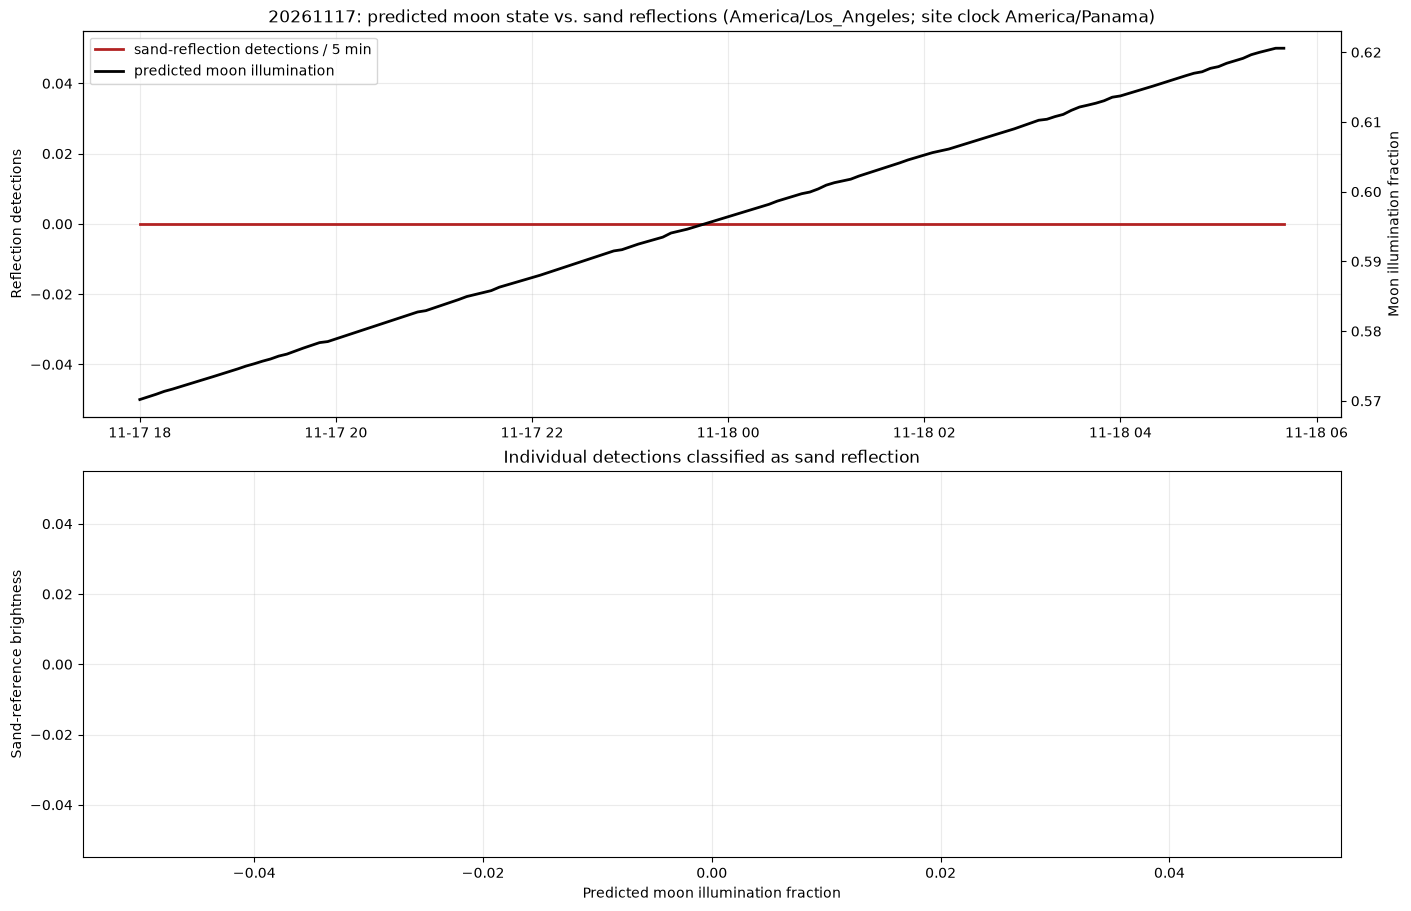

In [15]:
# Last-night moon state versus sand reflection
classified_csv = output_dir / 'bioluminescence_hits_classified.csv'
last_night = '20261117'
simulator_settings = pd.read_csv(output_dir / 'simulator_log.csv').iloc[0]
simulator_timezone = str(simulator_settings['simulator_timezone'])
display_timezone = str(simulator_settings['display_timezone'])
plot_chunks = []
for chunk in pd.read_csv(classified_csv, chunksize=100_000):
    night_chunk = chunk[
        (chunk['night'].astype(str) == last_night)
        & (chunk['classification'] != 'excluded_artifact')
    ]
    if not night_chunk.empty:
        plot_chunks.append(night_chunk)
plot_df = pd.concat(plot_chunks, ignore_index=True) if plot_chunks else pd.DataFrame()
if plot_df.empty:
    raise ValueError(f'No classified detections available for {last_night}')
plot_df['time'] = pd.to_datetime(plot_df['inferred_simulator_time'], errors='coerce')
plot_df = plot_df.dropna(subset=['time', 'moon_illumination_fraction'])
reflection = plot_df[plot_df['classification'] == 'reflection_suspect'].copy()
reflection['brightness'] = pd.to_numeric(reflection['reference_brightness'], errors='coerce')
reflection['moon_illumination_fraction'] = pd.to_numeric(reflection['moon_illumination_fraction'], errors='coerce')
reflection = reflection.dropna(subset=['brightness', 'moon_illumination_fraction'])
bins = pd.date_range(plot_df['time'].min().floor('5min'), plot_df['time'].max().ceil('5min'), freq='5min')
counts = reflection.set_index('time').resample('5min').size().reindex(bins, fill_value=0)
illumination = plot_df.set_index('time')['moon_illumination_fraction'].resample('5min').mean().reindex(bins).interpolate()
fig, axes = plt.subplots(2, 1, figsize=(14, 9), constrained_layout=True)
ax = axes[0]
ax2 = ax.twinx()
ax.step(bins, counts.values, where='mid', color='firebrick', linewidth=2, label='sand-reflection detections / 5 min')
ax2.plot(bins, illumination.values, color='black', linewidth=2, label='predicted moon illumination')
ax.set_ylabel('Reflection detections')
ax2.set_ylabel('Moon illumination fraction')
ax.set_title(f'{last_night}: predicted moon state vs. sand reflections ({display_timezone}; site clock {simulator_timezone})')
ax.grid(True, alpha=0.25)
lines, labels = ax.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax.legend(lines + lines2, labels + labels2, loc='upper left')
ax = axes[1]
ax.scatter(reflection['moon_illumination_fraction'], reflection['brightness'], s=12, alpha=0.5, color='firebrick', edgecolors='none')
ax.set_xlabel('Predicted moon illumination fraction')
ax.set_ylabel('Sand-reference brightness')
ax.set_title('Individual detections classified as sand reflection')
ax.grid(True, alpha=0.25)
moon_reflection_plot = output_dir / f'{last_night}_moon_vs_sand_reflection.png'
fig.savefig(moon_reflection_plot, dpi=180)
print(f'Saved {moon_reflection_plot}')
print(f'Rows plotted: {len(plot_df)}; sand reflections: {len(reflection)}')
plt.show()